In [2]:
# ================================================================
# 07 — SHAP Analyse: Modell A (Kaltmiete €/m²)
# ================================================================

import sys, os, time, warnings, joblib
sys.path.append('..')
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
import shap

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score

from src.data.preprocessing import (
    FEATURE_COLS, TARGET_PRICE,
    load_parquet, prepare_features, prepare_target_price, stratified_sample,
    prepare_features_for_trees,
)

RANDOM_STATE = 42
SAMPLE_FRAC  = 0.05
DATA_PATH    = '../data/processed/AUTO_final_enriched.parquet'
FIG_DIR      = '../reports/figures'
os.makedirs(FIG_DIR, exist_ok=True)

In [3]:
cols_needed = list(set(FEATURE_COLS + [TARGET_PRICE, "ajahr"]))
df_full = pd.read_parquet(DATA_PATH, columns=cols_needed)
print(f"df_full: {df_full.memory_usage(deep=True).sum() / 1e9:.2f} GB")

df_full: 4.92 GB


In [6]:
#df_full   = load_parquet(DATA_PATH)
df_sample = stratified_sample(df_full, frac=SAMPLE_FRAC, seed=RANDOM_STATE)

X = prepare_features(df_sample)
y = prepare_target_price(df_sample)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=df_sample["ajahr"],
)

# XGBoost kann keine str-Spalten verarbeiten -> Ordinal-Encoding (fit nur auf Train, kein Leakage)
X_train, X_test, ord_encoder = prepare_features_for_trees(X_train, X_test)

print(f"Train: {X_train.shape} | Test: {X_test.shape}")

Train: (460218, 32) | Test: (115055, 32)


In [4]:
xgb = joblib.load("../models/xgb_tuned_price.joblib")
lgbm = joblib.load("../models/lgbm_tuned_price.joblib")



Spearman ρ = 0.835  (p = 2.80e-09)
Weighted Kendall's τ = 0.844


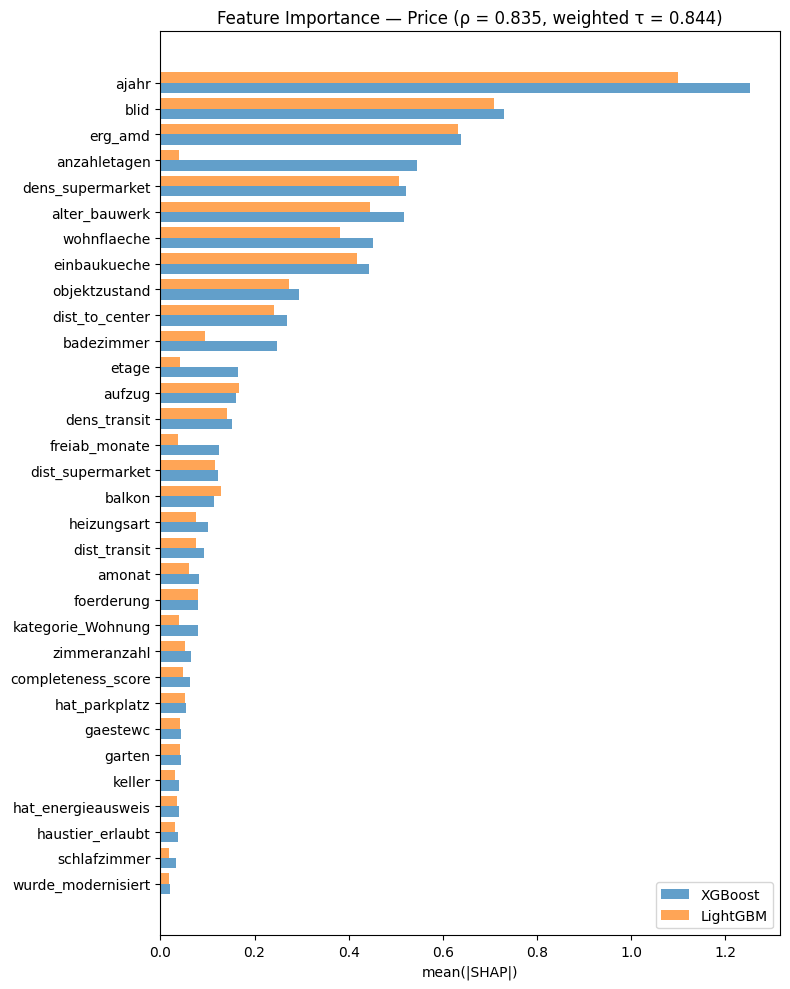

In [7]:
# --- SHAP für beide Modelle ---
from scipy.stats import spearmanr, weightedtau

X_shap = X_test.sample(n=min(10_000, len(X_test)), random_state=RANDOM_STATE)

shap_xgb  = shap.TreeExplainer(xgb).shap_values(X_shap)
shap_lgbm = shap.TreeExplainer(lgbm).shap_values(X_shap)

# --- Importance-Ranking vergleichen ---
imp = pd.DataFrame({
    'XGBoost':  pd.Series(np.abs(shap_xgb).mean(axis=0),  index=X_shap.columns),
    'LightGBM': pd.Series(np.abs(shap_lgbm).mean(axis=0), index=X_shap.columns),
})

rho, p = spearmanr(imp['XGBoost'].rank(), imp['LightGBM'].rank())
tau, _ = weightedtau(imp['XGBoost'], imp['LightGBM'])
print(f"Spearman ρ = {rho:.3f}  (p = {p:.2e})")
print(f"Weighted Kendall's τ = {tau:.3f}")

# --- Visueller Check ---
imp_sorted = imp.sort_values('XGBoost', ascending=True)
fig, ax = plt.subplots(figsize=(8, 10))
y_pos = range(len(imp_sorted))
ax.barh(y_pos, imp_sorted['XGBoost'], height=0.4, label='XGBoost', alpha=0.7)
ax.barh([y + 0.4 for y in y_pos], imp_sorted['LightGBM'], height=0.4, label='LightGBM', alpha=0.7)
ax.set_yticks([y + 0.2 for y in y_pos])
ax.set_yticklabels(imp_sorted.index)
ax.set_xlabel('mean(|SHAP|)')
ax.set_title(f'Feature Importance — Price (ρ = {rho:.3f}, weighted τ = {tau:.3f})')
ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/shap_importance_xgb_vs_lgbm_price.png", dpi=150, bbox_inches="tight")
plt.show()

# --- Für die spätere Price/Duration-Kombigrafik sichern (siehe unten) ---
# Pfad entspricht SHAPES_DIR, das erst weiter unten in Zelle 6 definiert wird
imp.to_parquet('../data/processed/importance_xgb_lgbm_price.parquet')

Spearman ρ = 0.854  (p = 5.08e-10)


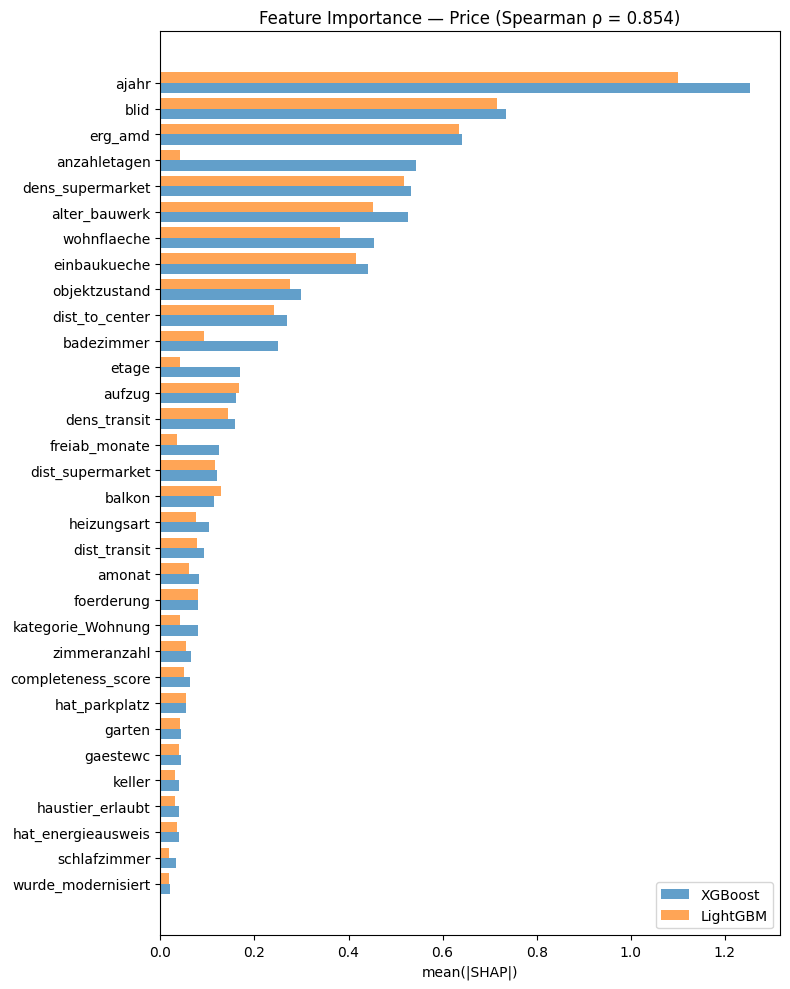

In [9]:
# --- SHAP für beide Modelle ---
from scipy.stats import spearmanr

X_shap = X_test.sample(n=min(5_000, len(X_test)), random_state=RANDOM_STATE)

shap_xgb  = shap.TreeExplainer(xgb).shap_values(X_shap)
shap_lgbm = shap.TreeExplainer(lgbm).shap_values(X_shap)

# --- Importance-Ranking vergleichen ---
imp = pd.DataFrame({
    'XGBoost':  pd.Series(np.abs(shap_xgb).mean(axis=0),  index=X_shap.columns),
    'LightGBM': pd.Series(np.abs(shap_lgbm).mean(axis=0), index=X_shap.columns),
})

rho, p = spearmanr(imp['XGBoost'].rank(), imp['LightGBM'].rank())
print(f"Spearman ρ = {rho:.3f}  (p = {p:.2e})")

# --- Visueller Check ---
imp_sorted = imp.sort_values('XGBoost', ascending=True)
fig, ax = plt.subplots(figsize=(8, 10))
y_pos = range(len(imp_sorted))
ax.barh(y_pos, imp_sorted['XGBoost'], height=0.4, label='XGBoost', alpha=0.7)
ax.barh([y + 0.4 for y in y_pos], imp_sorted['LightGBM'], height=0.4, label='LightGBM', alpha=0.7)
ax.set_yticks([y + 0.2 for y in y_pos])
ax.set_yticklabels(imp_sorted.index)
ax.set_xlabel('mean(|SHAP|)')
ax.set_title(f'Feature Importance — Price (Spearman ρ = {rho:.3f})')
ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/shap_importance_xgb_vs_lgbm_price.png", dpi=150, bbox_inches="tight")
plt.show()

In [32]:
# ── Pfade ──────────────────────────────────────────────────────────────────
SHAPES_DIR = '../data/processed'
MODELS_DIR = '../models'
SHAPE_FILES = {
    ('EBM',   'duration'):    'shapes_ebm_duration.parquet',
    ("EBM", "price"): "shapes_ebm_price.parquet"
}

# ── Laden ──────────────────────────────────────────────────────────────────
shapes = {}
for (model, target), fname in SHAPE_FILES.items():
    path = os.path.join(SHAPES_DIR, fname)
    if os.path.exists(path):
        shapes[(model, target)] = pd.read_parquet(path)
        n_feat = shapes[(model, target)]['feature'].nunique()
        print(f'  ✅ {fname}  ({n_feat} Features)')
    else:
        shapes[(model, target)] = None
        print(f'  ⏳ {fname} nicht vorhanden — NB03/04 zuerst ausführen')

missing = [k for k, v in shapes.items() if v is None]
if missing:
    print(f'\n⚠️  {len(missing)} Datei(en) fehlen. Nur verfügbare Daten werden analysiert.')
else:
    print('\n✅ Alle Shape-Parquets geladen — ready für Analyse.')

  ✅ shapes_ebm_duration.parquet  (32 Features)
  ✅ shapes_ebm_price.parquet  (32 Features)

✅ Alle Shape-Parquets geladen — ready für Analyse.


In [1]:
# ================================================================
# Cross-Method Ranking-Vergleich: EBM vs. XGBoost (Modell A Preis)
# ================================================================

# --- 1) EBM Importance aus explain_global() ---
ebm_model = joblib.load(os.path.join(MODELS_DIR, 'ebm_tuned_price.joblib'))
ebm_data = ebm_model.explain_global().data()

ebm_imp = pd.Series(ebm_data['scores'], index=ebm_data['names'])
main_mask = ~ebm_imp.index.str.contains(' & ', regex=False)
ebm_main = ebm_imp[main_mask]
ebm_inter = ebm_imp[~main_mask]

print(f"EBM Main Effects: {len(ebm_main)} | Interaktionen: {len(ebm_inter)}")
print(f"Anteil Interaktions-Importance: {ebm_inter.sum() / ebm_imp.sum():.1%}")

# --- 2) XGBoost SHAP Importance ---
xgb_model = joblib.load(os.path.join(MODELS_DIR, 'xgb_tuned_price.joblib'))

df_full = load_parquet('../data/processed/AUTO_final_enriched.parquet')
df_s    = stratified_sample(df_full, frac=0.05, seed=42)
X       = prepare_features(df_s)
X_train, X_test = train_test_split(
    X, test_size=0.20, random_state=42, stratify=df_s['ajahr']
)[:2]
X_train, X_test, _ = prepare_features_for_trees(X_train, X_test)

X_shap = X_test.sample(n=20_000, random_state=42)
shap_vals = shap.TreeExplainer(xgb_model).shap_values(X_shap)
xgb_imp = pd.Series(np.abs(shap_vals).mean(axis=0), index=X_shap.columns)

# --- 3) Ranking + Spearman ---
common = ebm_main.index.intersection(xgb_imp.index)
imp = pd.DataFrame({'EBM': ebm_main[common], 'XGBoost': xgb_imp[common]})

rho, p = spearmanr(imp['EBM'].rank(), imp['XGBoost'].rank())
print(f"\nSpearman ρ (EBM vs. XGBoost, Modell A): {rho:.3f}  (p = {p:.2e})")

# --- 4) Plot ---
imp_sorted = imp.sort_values('XGBoost', ascending=True)
fig, ax = plt.subplots(figsize=(9, 11))
y_pos = np.arange(len(imp_sorted))
ax.barh(y_pos - 0.2, imp_sorted['EBM'] / imp_sorted['EBM'].max(),
        height=0.4, label='EBM (normalized)', color='#EF553B', alpha=0.75)
ax.barh(y_pos + 0.2, imp_sorted['XGBoost'] / imp_sorted['XGBoost'].max(),
        height=0.4, label='XGBoost (normalized)', color='#636EFA', alpha=0.75)
ax.set_yticks(y_pos)
ax.set_yticklabels(imp_sorted.index)
ax.set_xlabel('Normalized Feature Importance')
ax.set_title(f'EBM vs. XGBoost — Feature Importance Ranking (Price)')
ax.legend()
ax.grid(True, axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/ranking_ebm_vs_xgb_price.png', dpi=150, bbox_inches='tight')
plt.show()

imp.to_parquet(f'{SHAPES_DIR}/importance_ranking_price.parquet')

NameError: name 'joblib' is not defined

In [18]:
from scipy.stats import weightedtau
tau, _ = weightedtau(imp['EBM'], imp['XGBoost'])

tau

np.float64(0.732806744160929)

In [24]:
# Am Ende des Price-Ranking-Notebooks:
X_shap.to_parquet(f'{SHAPES_DIR}/xshap_sample_price.parquet')
pd.DataFrame(shap_vals, columns=X_shap.columns).to_parquet(
    f'{SHAPES_DIR}/shap_values_price.parquet'
)

# Am Ende des Duration-Ranking-Notebooks analog mit _dur

In [33]:
X_shap_price    = pd.read_parquet(f'{SHAPES_DIR}/xshap_sample_price.parquet')
shap_vals_price = pd.read_parquet(f'{SHAPES_DIR}/shap_values_price.parquet').values
X_shap_dur      = pd.read_parquet(f'{SHAPES_DIR}/xshap_sample_dur.parquet')
shap_vals_dur   = pd.read_parquet(f'{SHAPES_DIR}/shap_values_dur.parquet').values


# ================================================================
# 2×2 Panel: EBM Shape vs. XGBoost SHAP Dependence, Price vs. Duration
# ================================================================
from scipy.interpolate import interp1d

PLOTS_DIR = '../reports/figures/feature-plots'
os.makedirs(PLOTS_DIR, exist_ok=True)


def plot_feature_panel(feature, save=True, show=True):
    """
    2x2 Panel für ein Feature:
        Zeile 1: EBM Shape Function (Price | Duration)
        Zeile 2: XGBoost SHAP Dependence (Price | Duration)
    """
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    
    # === EBM Shape Functions (Zeile 1) ===
    for col, target in enumerate(['price', 'duration']):
        ax = axes[0, col]
        df_shape = shapes.get(('EBM', target))
        
        if df_shape is None:
            ax.text(0.5, 0.5, 'EBM shape not available',
                    ha='center', va='center', transform=ax.transAxes)
            continue
        
        sub = df_shape[df_shape['feature'] == feature].sort_values('x')
        if sub.empty:
            ax.text(0.5, 0.5, f'{feature} not in EBM',
                    ha='center', va='center', transform=ax.transAxes)
            continue
        
        ax.plot(sub['x'], sub['y'], color='#EF553B', linewidth=2)
        ax.axhline(0, color='gray', linewidth=0.8, linestyle='--', alpha=0.5)
        ax.set_title(f'EBM — {target.capitalize()}', fontsize=11)
        ax.set_xlabel(feature)
        ax.set_ylabel('Contribution')
        ax.grid(True, alpha=0.3)
    
    # === XGBoost SHAP Dependence (Zeile 2) ===
    shap_data = {
        'price':    (X_shap_price, shap_vals_price),
        'duration': (X_shap_dur,   shap_vals_dur),
    }
    
    for col, target in enumerate(['price', 'duration']):
        ax = axes[1, col]
        X_s, shap_v = shap_data[target]
        
        if feature not in X_s.columns:
            ax.text(0.5, 0.5, f'{feature} not in XGB',
                    ha='center', va='center', transform=ax.transAxes)
            continue
        
        idx = X_s.columns.get_loc(feature)
        x_vals = X_s[feature].values
        y_vals = shap_v[:, idx]
        
        ax.scatter(x_vals, y_vals, alpha=0.3, s=8, color='#636EFA')
        ax.axhline(0, color='gray', linewidth=0.8, linestyle='--', alpha=0.5)
        ax.set_title(f'XGBoost SHAP — {target.capitalize()}', fontsize=11)
        ax.set_xlabel(feature)
        ax.set_ylabel('SHAP value')
        ax.grid(True, alpha=0.3)
    
    # === x-Achsen spaltenweise angleichen ===
    for col in range(2):
        x_mins = [axes[row, col].get_xlim()[0] for row in range(2)]
        x_maxs = [axes[row, col].get_xlim()[1] for row in range(2)]
        for row in range(2):
            axes[row, col].set_xlim(min(x_mins), max(x_maxs))
    
    fig.suptitle(f'Feature: {feature}', fontsize=13, fontweight='bold', y=1.00)
    plt.tight_layout()
    
    if save:
        fig.savefig(f'{PLOTS_DIR}/panel_{feature}.png', dpi=150, bbox_inches='tight')
    if show:
        plt.show()
    else:
        plt.close(fig)
    
    return fig

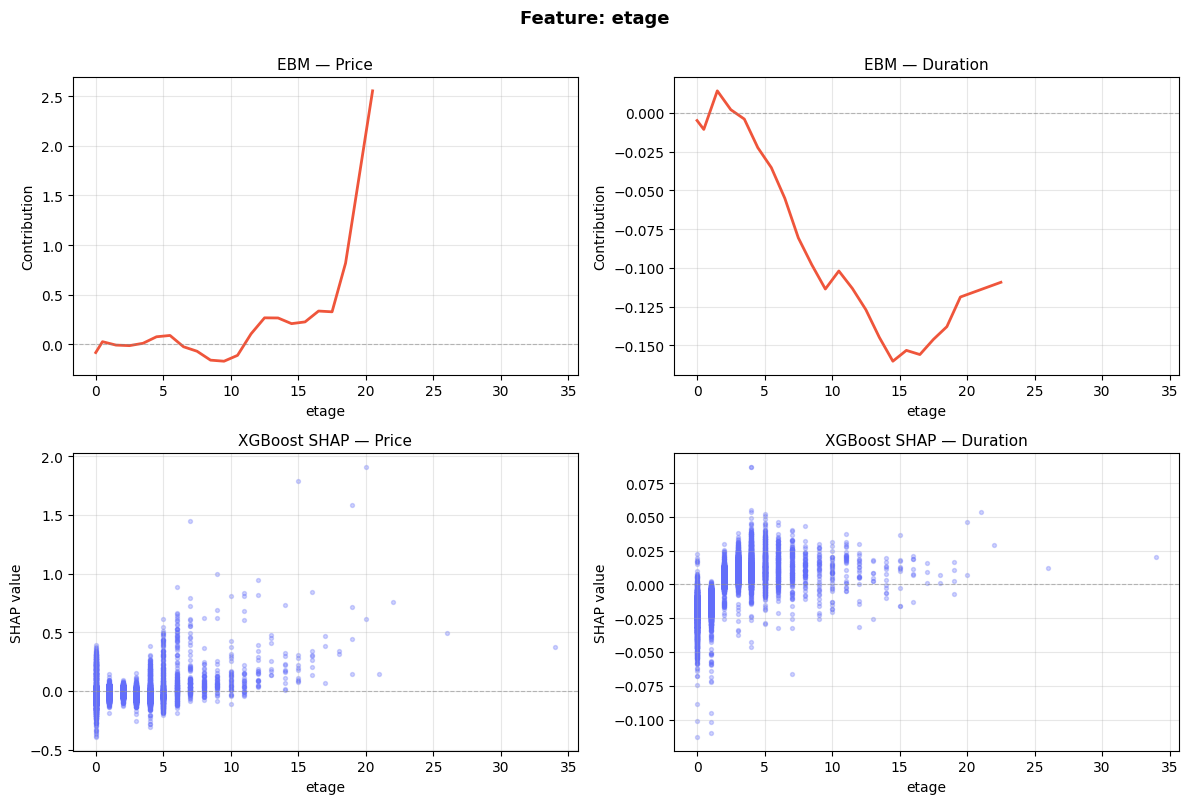

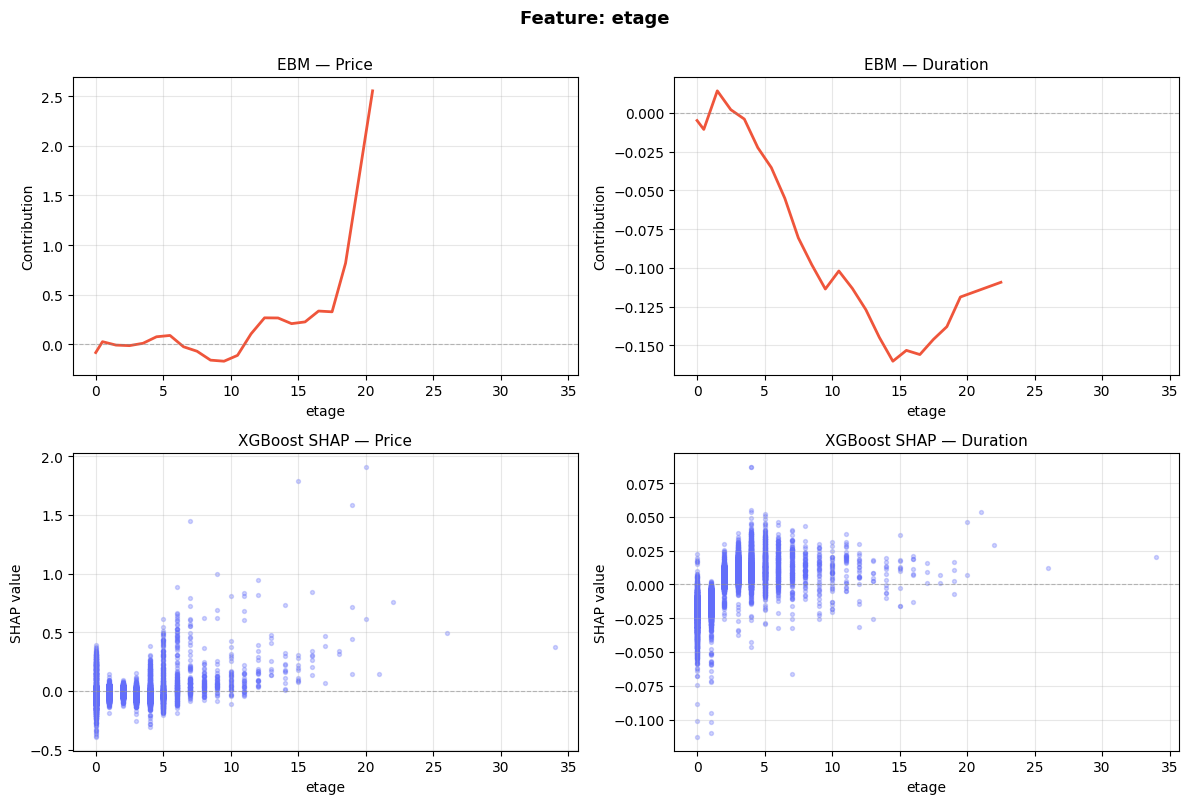

In [40]:
plot_feature_panel('etage')

In [41]:
all_features = sorted(shapes[('EBM', 'price')]['feature'].unique())
for feat in all_features:
    plot_feature_panel(feat, save=True, show=False)
print(f"{len(all_features)} Panels gespeichert in {PLOTS_DIR}")

32 Panels gespeichert in ../reports/figures/feature-plots


In [44]:
import pandas as pd

all_features = sorted(shapes[('EBM', 'price')]['feature'].unique())

classification = pd.DataFrame(
    index=all_features,
    columns=['cross_method', 'cross_target', 'notes']
)
classification.index.name = 'feature'

In [77]:
classification.loc['zimmeranzahl']  = ['agree', "concordant", 
    'both curves move together across most of the range; brief sign divergences']

In [79]:
print(classification.to_latex('../reports/feature_classification.tex',
                        na_rep='—', column_format='lll',
                        caption='Cross-target classification of all features.',
                        label='tab:classification'))

None


In [1]:
import pandas as pd

data = {
    'ajahr':               ('agree',    'opposing',           'Reflects tightening rental market 2007-2025; rising prices coincide with shorter listing durations.'),
    'alter_bauwerk':       ('agree',    'concordant',         'U-shape both targets; Neubau and Altbau segments show both price premium and longer listing duration, consistent with niche market segments.'),
    'amonat':              ('partial',  'inconclusive',  'Weak positive effect both targets.'),
    'anzahletagen':        ('partial',  'concordant (weak)',  'Weak positive effect both targets; EBM unreliable beyond 15 floors (sparse bins).'),
    'aufzug':              ('agree',    'concordant',         'Elevator increases price and marginally increases listing duration; duration effect near negligible.'),
    'badezimmer':          ('partial',  'inconclusive',       'Clear, agreeing price effect; duration effect differs (EBM shows weak non-monotonic structure, XGBoost shows none).'),
    'balkon':              ('agree',    'opposing',           'Balcony increases price and decreases listing duration.'),
    'blid':                ('partial',  'opposing',           'Nominal feature, curve interpretation limited; clear effects for single states.'),
    'completeness_score':  ('agree',    'opposing',           'Counterintuitive: higher listing quality associates with lower price, longer duration.'),
    'dens_supermarket':    ('partial',  'opposing',           'Agreement in core range (0-25); unstable in sparse tail (>25).'),
    'dens_transit':        ('partial',  'opposing',           'Higher transit-stop density associates with lower price and longer duration - counterintuitive; possibly confounded with location type.'),
    'dist_supermarket':    ('agree',    'opposing',           'Clean, intuitive proximity effect: closer supermarket access commands price premium and shorter time-on-market.'),
    'dist_to_center':      ('agree',    'opposing',           'Both center and periphery command price premiums with shorter duration; suburban mid-range is least desirable.'),
    'dist_transit':        ('partial',  'inconclusive',           'Erratic on both methods, weak signal overall.'),
    'einbaukueche':        ('agree',    'opposing',           'Price premium and shorter duration.'),
    'erg_amd':             ('disagree', 'inconclusive',       'Unclear feature semantics; extreme values misaligned between methods.'),
    'etage':               ('partial',  'inconclusive',       'Price effect agrees; Duration direction disputed between methods (EBM shows decreasing, XGBoost shows increasing trend).'),
    'foerderung':          ('agree',    'opposing',           'Subsidized units: lower price, longer time-on-market.'),
    'freiab_monate':       ('agree',    'concordant',         'Strong effect both targets; unusually large duration magnitude vs. other features.'),
    'gaestewc':            ('partial',  'concordant',         'Both effects positive but negligible in magnitude; likely low practical relevance.'),
    'garten':              ('agree',    'opposing',           'Weak effect.'),
    'hat_energieausweis':  ('agree',    'opposing',           'Counterintuitive direction: having an energy certificate associates with lower price and longer duration; magnitude small.'),
    'hat_parkplatz':       ('agree',    'concordant',         'Both effects positive but duration magnitude negligible; price effect modest.'),
    'haustier_erlaubt':    ("partial",       "mixed",          'Encoding inconsistency (3 categories vs. documented binary); excluded from detailed interpretation.'),
    'heizungsart':         ('disagree', 'inconclusive',       'Nominal categorical feature; shape interpretation not meaningful.'),
    'kategorie_Wohnung':   ('disagree', 'inconclusive',       'Nominal categorical feature; shape interpretation not meaningful.'),
    'keller':              ('agree',    'opposing',           'Counterintuitive: cellar associates with lower price and longer duration.'),
    'objektzustand':       ('partial',  'mixed',              'Price/Duration same sign in core range; EBM duration spike at high categories not confirmed by XGBoost; unreliable at range extremes.'),
    'schlafzimmer':        ('agree',    'concordant',         'Core range agrees both targets and models; tails sparse/unreliable.'),
    'wohnflaeche':         ('agree',    'mixed',              'Small apartments and large units both command price premium, while the mainstream mid-size segment sees falling prices with rising time-on-market.'),
    'wurde_modernisiert':  ('agree',    'opposing',           'Attractive amenity pattern like einbaukueche: price premium, shorter duration.'),
    'zimmeranzahl':        ('agree',    'concordant',         'Both curves move together across most of the range; brief sign divergence.'),
}

classification = pd.DataFrame.from_dict(
    data, orient='index', columns=['cross_method', 'cross_target', 'notes']
)
classification.index.name = 'feature'

# Kurzer Sanity-Check
print(f"Anzahl Features: {len(classification)}")
print(f"Fehlende cross_method: {classification['cross_method'].isna().sum()}")
print(classification[classification['cross_method'].isna()])

Anzahl Features: 32
Fehlende cross_method: 0
Empty DataFrame
Columns: [cross_method, cross_target, notes]
Index: []


In [2]:
# ================================================================
# Aggregierte Auswertung der Feature-Klassifikation
# ================================================================

# --- 1) Thematische Gruppen zuweisen ---
theme_map = {
    # Dwelling Structure
    'wohnflaeche': 'Dwelling', 'zimmeranzahl': 'Dwelling',
    'schlafzimmer': 'Dwelling', 'badezimmer': 'Dwelling',
    'kategorie_Wohnung': 'Dwelling', 'etage': 'Dwelling',
    'anzahletagen': 'Dwelling',
    # Building Age & Condition
    'alter_bauwerk': 'Building',
    'wurde_modernisiert': 'Building', 'objektzustand': 'Building',
    # Amenities
    'einbaukueche': 'Amenities', 'aufzug': 'Amenities',
    'balkon': 'Amenities', 'garten': 'Amenities', 'keller': 'Amenities',
    'gaestewc': 'Amenities', 'hat_parkplatz': 'Amenities',
    'haustier_erlaubt': 'Amenities',
    # Location
    'blid': 'Location', 'dist_to_center': 'Location',
    'dist_supermarket': 'Location', 'dens_supermarket': 'Location',
    'dist_transit': 'Location', 'dens_transit': 'Location',
    # Energy
    'hat_energieausweis': 'Energy', 'heizungsart': 'Energy',
    'erg_amd': 'Energy', 
    # Market/Meta
    'amonat': 'Meta', 'freiab_monate': 'Meta',
    'completeness_score': 'Meta', 'ajahr': 'Meta', 'foerderung': 'Meta',
}

classification['theme'] = classification.index.map(theme_map)

# Check: alle Features zugeordnet?
missing = classification[classification['theme'].isna()].index.tolist()
if missing:
    print(f"Fehlende Zuordnung: {missing}")


# --- 2) Gesamtübersicht: Cross-Method und Cross-Target ---
print("=" * 60)
print("GESAMTVERTEILUNG")
print("=" * 60)

print("\nCross-Method (Modellübereinstimmung):")
cm_dist = classification['cross_method'].value_counts(normalize=True) * 100
print(cm_dist.round(1).to_string())

print("\nCross-Target (Preis vs. Laufzeit):")
ct_dist = classification['cross_target'].value_counts(normalize=True) * 100
print(ct_dist.round(1).to_string())


# --- 3) Kreuztabelle Method x Target ---
print("\n" + "=" * 60)
print("KREUZTABELLE Method × Target (absolute Zählungen)")
print("=" * 60)
crosstab = pd.crosstab(
    classification['cross_method'],
    classification['cross_target'],
    margins=True
)
print(crosstab)


# --- 4) Thematische Auswertung ---
print("\n" + "=" * 60)
print("PRO THEMA — Cross-Target-Verteilung")
print("=" * 60)
theme_target = pd.crosstab(
    classification['theme'],
    classification['cross_target'],
    normalize='index'
) * 100
print(theme_target.round(1))

print("\n" + "=" * 60)
print("PRO THEMA — Cross-Method-Verteilung")
print("=" * 60)
theme_method = pd.crosstab(
    classification['theme'],
    classification['cross_method'],
    normalize='index'
) * 100
print(theme_method.round(1))


# --- 5) Robustheitsmetriken für den Text ---
print("\n" + "=" * 60)
print("KENNZAHLEN FÜR FLIESSTEXT")
print("=" * 60)

n_total = len(classification)
n_agree = (classification['cross_method'] == 'agree').sum()
n_robust = classification['cross_method'].isin(['agree', 'partial']).sum()
n_interpretable = (~classification['cross_target'].isin(['inconclusive', None])).sum()

print(f"Anzahl Features gesamt: {n_total}")
print(f"Cross-Method 'agree': {n_agree} ({n_agree/n_total:.1%})")
print(f"Cross-Method robust (agree + partial): {n_robust} ({n_robust/n_total:.1%})")
print(f"Interpretierbare cross-target Klassifikation: {n_interpretable} ({n_interpretable/n_total:.1%})")

# Verteilung nur unter interpretierbaren Features
interp = classification[~classification['cross_target'].isin(['inconclusive', None])]
print(f"\nUnter den {len(interp)} interpretierbaren Features:")
for cat, share in (interp['cross_target'].value_counts(normalize=True) * 100).items():
    print(f"  {cat}: {share:.1f}%")

# --- 4b) Themen-Kurzbefunde automatisch ---
print("\n" + "=" * 60)
print("THEMA-KURZBEFUNDE")
print("=" * 60)

for theme in classification['theme'].dropna().unique():
    sub = classification[classification['theme'] == theme]
    n = len(sub)
    dist = sub['cross_target'].value_counts(normalize=True) * 100
    dominant_cat = dist.idxmax()
    dominant_pct = dist.max()
    method_agree_pct = (sub['cross_method'] == 'agree').mean() * 100
    print(f"\n{theme} (n={n}):")
    print(f"  Cross-target dominant: {dominant_cat} ({dominant_pct:.0f}%)")
    print(f"  Cross-method agree rate: {method_agree_pct:.0f}%")
    print(f"  Features: {', '.join(sub.index.tolist())}")

GESAMTVERTEILUNG

Cross-Method (Modellübereinstimmung):
cross_method
agree       56.2
partial     34.4
disagree     9.4

Cross-Target (Preis vs. Laufzeit):
cross_target
opposing             43.8
concordant           21.9
inconclusive         21.9
mixed                 9.4
concordant (weak)     3.1

KREUZTABELLE Method × Target (absolute Zählungen)
cross_target  concordant  concordant (weak)  inconclusive  mixed  opposing  \
cross_method                                                                 
agree                  6                  0             0      1        11   
disagree               0                  0             3      0         0   
partial                1                  1             4      2         3   
All                    7                  1             7      3        14   

cross_target  All  
cross_method       
agree          18  
disagree        3  
partial        11  
All            32  

PRO THEMA — Cross-Target-Verteilung
cross_target  concordant

In [4]:
3/7

0.42857142857142855